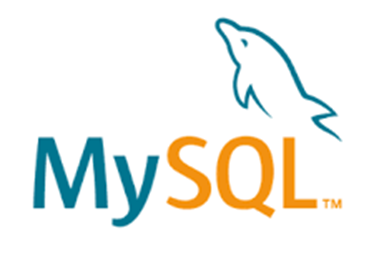

# Introdução ao MySQL com Python

#### Passo 1: Instalar bibliotecas

In [33]:
#%pip install pymysql

#### Passo 2: Importar bibliotecas

In [34]:
import pymysql

#### Passo 3: Conectar no MySQL

In [35]:
# Cria conexão com banco de dados
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root"
)
cursor = conn.cursor()

#### Passo 4:  Criar banco

In [36]:
cursor.execute("CREATE DATABASE IF NOT EXISTS mohammadteste")
print("Banco criado com sucesso!")

Banco criado com sucesso!


#### Passo 5: Conferir no Workbench
- Abra o **MySQL Workbench**
- No painel esquerdo (Schemas), clique em Refresh
- Você deve ver o banco `meubanco`

#### Passo 6: Verificar conexão

In [37]:
# Encerrar conexão com banco de dados
conn.close()

In [38]:
# Testa se a conexão está ativa
if conn.open:
    print("Conexão ativa!")
else:
    print('Banco de dados desconectado')

Banco de dados desconectado


In [39]:
# Criar conexão 
if not conn.open:
    conn.ping(reconnect=True)

C:\Users\41228408807\AppData\Local\Temp\ipykernel_23112\628939375.py:3: DeprecationWarning: The 'reconnect' argument is deprecated. Create a new connection if you want to reconnect.
  conn.ping(reconnect=True)


In [40]:
# Verificar em qual banco está conectado
cursor.execute("SELECT DATABASE();")
cursor.fetchone()

(None,)

In [41]:
# Verificar bancos existentes
cursor.execute("SHOW DATABASES;")
cursor.fetchall()

(('clinevida',),
 ('information_schema',),
 ('mohammadteste',),
 ('mysql',),
 ('performance_schema',),
 ('sys',),
 ('techburguer',),
 ('techdelivery',),
 ('world',))

In [43]:
# Conectar ao banco existente
cursor.execute("USE mohammadteste")

0

In [44]:
# Verificar em qual banco está conectado
cursor.execute("SELECT DATABASE();")
cursor.fetchone()

('mohammadteste',)

In [45]:
# Encerrar conexão com banco de dados
conn.close()

In [46]:
# Forma completa para conectar
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root",
    database="mohammadteste"  
)
cursor = conn.cursor()

In [47]:
# Verificar em qual banco está conectado
cursor.execute("SELECT DATABASE();")
cursor.fetchone()

('mohammadteste',)

#### Passo 7: Criar tabela

In [48]:
# Conecta com banco de dados
cursor = conn.cursor()

# Cria Tabela
cursor.execute("""
CREATE TABLE IF NOT EXISTS produtos (
    id INT AUTO_INCREMENT PRIMARY KEY,
    titulo VARCHAR(255),
    preco DECIMAL(10,2),
    categoria VARCHAR(100)
)
""")
print("Tabela criada com sucesso!")

Tabela criada com sucesso!


#### Passo 8: Inserir dados

In [49]:
dados = [
    ("Notebook Dell", 3500.00, "Eletrônicos"),
    ("Smartphone Samsung", 2100.00, "Eletrônicos"),
    ("Livro Python", 89.90, "Livros"),
    ("Monitor LG", 899.00, "Eletrônicos")
]
cursor.executemany("INSERT INTO produtos (titulo, preco, categoria) VALUES (%s, %s, %s)", dados)
conn.commit()
print("Dados inseridos!")

Dados inseridos!


In [50]:
# Encerrar conexão com banco de dados
conn.close()

#### Passo 9: Visualizar no Workbench
- Clique em `meubanco` → abra a aba de queries.

Rode: `SELECT * FROM produtos;`

#### Passo 9: inserindo novos dados pelo Workbench
Ainda no Workbench, rode:

`INSERT INTO produtos (titulo, preco, categoria)`

`VALUES ("Mouse Gamer", 199.90, "Eletrônicos");`

#### Passo 10: Consulta de teste no Python

In [51]:
# Conecta com Banco de dados
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root",
    database="mohammadteste"  
)
cursor = conn.cursor()

In [52]:
cursor.execute("SELECT * FROM produtos")
for row in cursor.fetchall():
    print(row)

(1, 'Notebook Dell', Decimal('3500.00'), 'Eletrônicos')
(2, 'Smartphone Samsung', Decimal('2100.00'), 'Eletrônicos')
(3, 'Livro Python', Decimal('89.90'), 'Livros')
(4, 'Monitor LG', Decimal('899.00'), 'Eletrônicos')
(5, 'Mouse Gamer', Decimal('199.90'), 'Eletrônicos')


# Neste exercício exploramos Python e Workbench no mesmo banco MySQL
- O banco é o mesmo: Python e Workbench são apenas **duas portas de acesso**.
- Você pode **criar, inserir e consultar** dados em um ambiente e ver os resultados no outro.
- Isso mostra a importância de **separar a camada de aplicação (Python) da camada de dados (MySQL).**

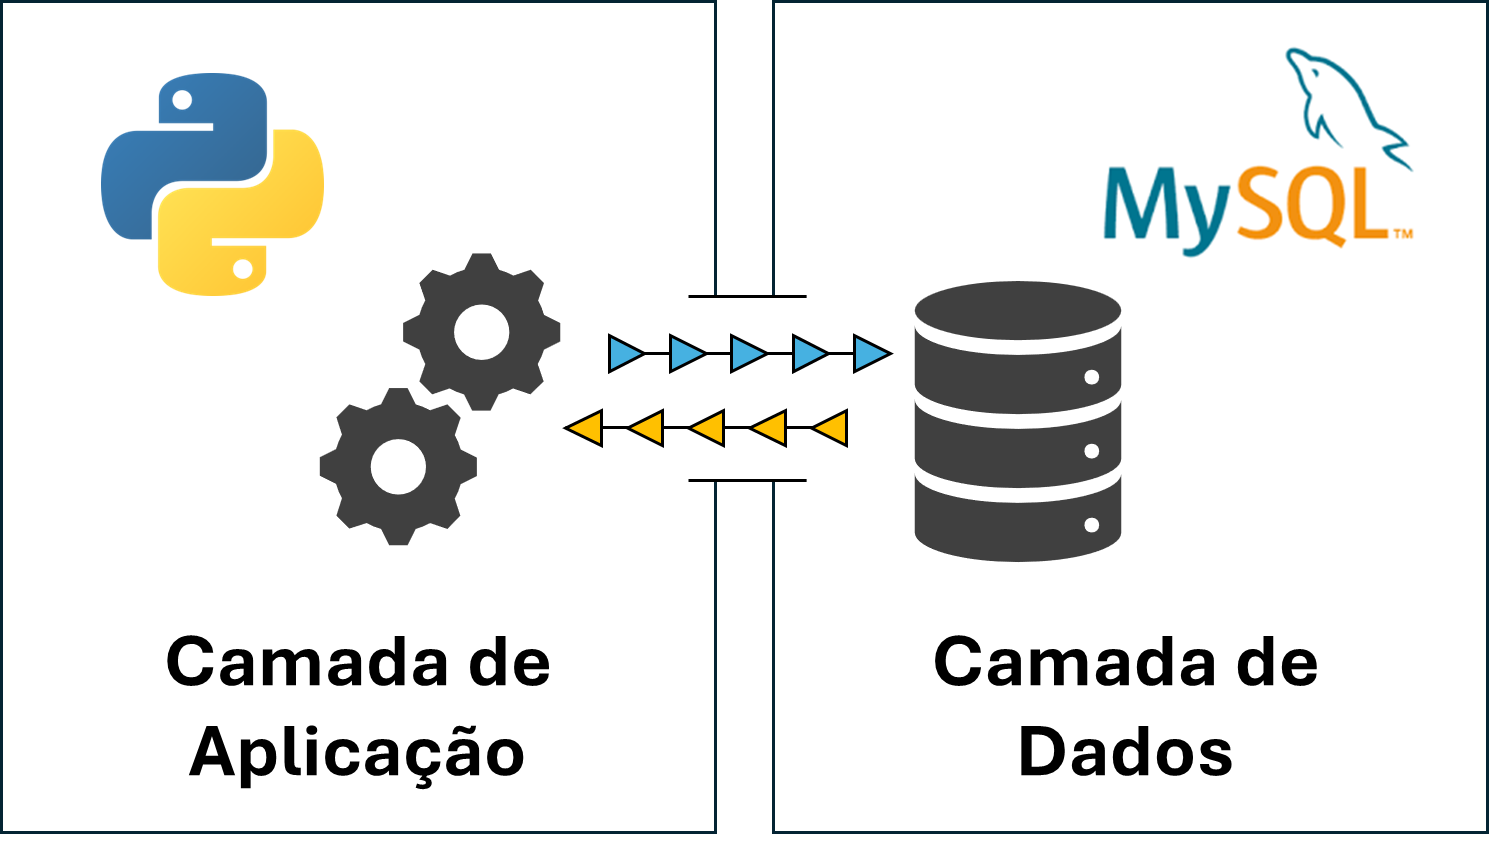

### Onde o banco de dados fica salvo? 

- Diferente do **SQLite** em que o banco é criado como **um arquivo** `.db` **no diretório atual** (mesma pasta do notebook/script)
- O **MySQL guarda os bancos em uma pasta interna do servido**. Geralmente em:
 
  `C:\ProgramData\MySQL\MySQL Server 8.0\Data\`
  
 **Atenção:** 
 - Essa pasta é oculta, tem que habilitar **Mostrar arquivos ocultos**
 - Você **não manipula diretamente esses arquivos**, sempre acessa via o servidor MySQL (Workbench, Python, terminal).

### Apagar o banco de dados

- Atenção! Esse comando apaga todo o banco de dados (tabelas, dados, índices, etc.).

- **Não há undo** – depois de rodar, não tem como recuperar a não ser que você tenha backup.

In [53]:
# Exclui banco de dados
cursor.execute("DROP DATABASE IF EXISTS meubanco")

# Salvar. commit() grava de forma definitiva as alterações feitas no banco de dados na transação atual
conn.commit()

# Fecha o canal de envio de comandos
cursor.close()

# Encerrar conexão com banco de dados
conn.close()

---
# Exercícios de fixação

> **Orientação:** execute cada exercício em sequência. Quando necessário, confira o resultado também no MySQL Workbench.


## Exercício 1: Conexão com o MySQL

Crie uma conexão com o servidor MySQL utilizando `pymysql.connect()`. Depois:

1. crie um cursor;
2. execute `SELECT DATABASE();`;
3. imprima o resultado;
4. verifique se a conexão está ativa.

**Objetivo:** praticar conexão, cursor e execução de uma consulta simples.


In [ ]:
# Escreva sua solução aqui



## Exercício 2: Criando um banco para os exercícios

Crie um banco de dados chamado `loja_treinamento`, caso ele ainda não exista. Em seguida, selecione esse banco com o comando `USE` e confirme, por meio de `SELECT DATABASE();`, que ele está ativo.

**Objetivo:** praticar `CREATE DATABASE`, `USE` e verificação do banco selecionado.


In [ ]:
# Escreva sua solução aqui



## Exercício 3: Criando uma tabela

No banco `loja_treinamento`, crie uma tabela chamada `clientes` com a seguinte estrutura:

| Campo | Tipo | Regra |
|---|---|---|
| `id` | INT | chave primária e `AUTO_INCREMENT` |
| `nome` | VARCHAR(150) | nome do cliente |
| `cidade` | VARCHAR(100) | cidade do cliente |
| `idade` | INT | idade do cliente |

Utilize `CREATE TABLE IF NOT EXISTS`.

**Objetivo:** praticar criação de tabelas e definição de campos.


In [ ]:
# Escreva sua solução aqui



## Exercício 4: Inserindo vários registros

Insira **pelo menos cinco clientes** na tabela `clientes`. Utilize uma lista de tuplas em Python e o método `executemany()`. Ao final, confirme a transação com `conn.commit()`.

Exemplo de estrutura dos dados:

```python
dados = [
    ("Ana", "São Paulo", 28),
    ("Carlos", "Campinas", 35)
]
```

Acrescente pelo menos três registros diferentes dos apresentados no exemplo.

**Objetivo:** praticar inserção em lote e persistência com `commit()`.


In [ ]:
# Escreva sua solução aqui



## Exercício 5: Consultando os dados

Faça uma consulta que retorne **todos os registros** da tabela `clientes`. Utilize `fetchall()` e um laço `for` para imprimir cada linha separadamente.

Depois, responda observando a saída:

1. Quantos clientes foram cadastrados?
2. Qual informação aparece na primeira posição de cada tupla retornada?

**Objetivo:** praticar `SELECT`, `fetchall()` e leitura do resultado no Python.


In [ ]:
# Escreva sua solução aqui



## Exercício 6: Consultas com filtros

Realize as seguintes consultas na tabela `clientes`:

1. exiba apenas os clientes com idade maior que 30 anos;
2. exiba apenas os clientes de uma cidade escolhida por você;
3. exiba somente as colunas `nome` e `cidade`.

Imprima os resultados de cada consulta.

**Objetivo:** praticar consultas `SELECT` com seleção de colunas e filtros.


In [ ]:
# Consulta 1


# Consulta 2


# Consulta 3



## Exercício 7: Cadastro de produtos

Crie uma tabela chamada `produtos_treinamento` com os campos `id`, `titulo`, `preco` e `categoria`, seguindo a estrutura utilizada anteriormente no notebook. Depois:

1. cadastre pelo menos seis produtos de duas ou mais categorias;
2. confirme os dados com `commit()`;
3. consulte todos os produtos;
4. mostre apenas os produtos de uma categoria escolhida por você.

**Objetivo:** integrar criação de tabela, inserção e consulta em uma única atividade.


In [ ]:
# Escreva sua solução aqui



## Exercício 8: Python e Workbench no mesmo banco

Este exercício deve ser realizado utilizando os dois ambientes.

1. Pelo **Python**, insira um novo produto em `produtos_treinamento`.
2. No **MySQL Workbench**, execute uma consulta e verifique se o produto aparece.
3. Pelo **Workbench**, insira outro produto.
4. Volte ao **Python**, execute novamente o `SELECT` e confirme se o novo registro aparece.

Ao final, explique em poucas linhas por que Python e Workbench conseguem visualizar os mesmos dados.

**Objetivo:** consolidar a diferença entre o banco de dados MySQL e as ferramentas utilizadas para acessá-lo.


In [ ]:
# Use esta célula para inserir/consultar os dados pelo Python



**Resposta conceitual:**

Escreva aqui sua explicação.


## Desafio final

Sem copiar diretamente os exemplos anteriores, desenvolva um pequeno cadastro para um contexto de sua escolha, como **livros, alunos, filmes, veículos ou funcionários**. Sua solução deve:

1. criar uma nova tabela;
2. possuir uma chave primária com `AUTO_INCREMENT`;
3. possuir pelo menos três atributos além do `id`;
4. inserir pelo menos cinco registros com `executemany()`;
5. executar uma consulta que mostre todos os registros;
6. executar pelo menos uma consulta com filtro;
7. utilizar `commit()` após as inserções;
8. fechar o cursor e a conexão ao final.

**Objetivo:** aplicar de forma integrada os conceitos trabalhados no notebook.


In [ ]:
# Desenvolva aqui sua solução completa

